In [17]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mhkit.wave.io.ndbc import read_file
from mhkit.wave.resource import energy_period
from os.path import join as pjoin
import numpy as np
import pandas as pd
from tabulate import tabulate

import warnings
np.warnings = warnings

## set colorblind-friendly colormap for plots
plt.style.use('tableau-colorblind10')

In [18]:
raw_data_dir = './'

In [19]:
report_image_dir = '../90-reports/dynamic-modelling-mab/images'
save_images = False
def save_fig(fig, name):
    if save_images:
        fig.savefig(pjoin(report_image_dir, name + ".eps"), format="eps")
        fig.savefig(pjoin(report_image_dir, name + ".png"), format="png")

In [20]:
ndbc_months = ["04", "05"]

ndbc_data_frames = []
ndbc_data_resampled = []
for m in ndbc_months:
    ndbc_data_raw, ndbc_metadata = read_file(pjoin(raw_data_dir, "ndbc", "ndbc_44014_stdmet_2024-"+m+".txt"))
    ndbc_data_frames.append(ndbc_data_raw)

ndbc_data = pd.concat(ndbc_data_frames).to_xarray().rename({"index":"time"})

for q,u in ndbc_metadata.items():
    ndbc_data[q].attrs = {'units': u}

ndbc_data.WVHT.attrs["long_name"] = "Sig Wave Height"
ndbc_data.DPD.attrs["long_name"] = "Peak Period"

print(ndbc_data)


<xarray.Dataset>
Dimensions:  (time: 8784)
Coordinates:
  * time     (time) datetime64[ns] 2024-04-01 ... 2024-05-31T23:50:00
Data variables: (12/13)
    WDIR     (time) float64 70.0 71.0 76.0 80.0 73.0 ... 334.0 319.0 322.0 315.0
    WSPD     (time) float64 4.2 3.8 3.5 3.1 2.9 3.2 ... 2.1 2.0 1.7 1.9 1.6 1.4
    GST      (time) float64 5.0 4.5 4.5 3.7 3.4 4.0 ... 2.6 2.5 2.1 2.2 2.0 1.8
    WVHT     (time) float64 nan 0.86 nan nan 0.84 nan ... 0.75 nan nan 0.68 nan
    DPD      (time) float64 nan 7.14 nan nan 7.69 nan ... 4.55 nan nan 4.55 nan
    APD      (time) float64 nan 5.22 nan nan 5.51 nan ... 4.22 nan nan 4.24 nan
    ...       ...
    PRES     (time) float64 1.015e+03 1.015e+03 ... 1.023e+03 1.023e+03
    ATMP     (time) float64 10.8 10.9 11.0 11.2 11.2 ... 17.8 17.8 17.7 17.6
    WTMP     (time) float64 9.4 9.4 9.3 9.3 9.3 9.3 ... 17.1 17.1 17.1 17.1 17.0
    DEWP     (time) float64 9.9 10.1 10.2 10.3 10.3 ... 15.7 15.8 16.0 15.8 15.6
    VIS      (time) float64 nan nan nan 

c:\Users\jtgrasb\AppData\Local\anaconda3\Lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(
c:\Users\jtgrasb\AppData\Local\anaconda3\Lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(


In [21]:
# energy period
ndbc_spec_data_all = []
for m in ndbc_months:
    ndbc_spec_data, _ = read_file(pjoin(raw_data_dir, "ndbc", "ndbc_44014_swden_2024-"+m+".txt"))
    ndbc_spec_data_all.append(ndbc_spec_data)

ndbc_energy_period = energy_period(pd.concat(ndbc_spec_data_all).transpose()).to_xarray().rename({"index":"time"})
print(ndbc_energy_period)

c:\Users\jtgrasb\AppData\Local\anaconda3\Lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(
c:\Users\jtgrasb\AppData\Local\anaconda3\Lib\site-packages\mhkit\wave\io\ndbc.py:99: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv(


<xarray.Dataset>
Dimensions:  (time: 2896)
Coordinates:
  * time     (time) datetime64[ns] 2024-04-01T00:10:00 ... 2024-05-31T23:40:00
Data variables:
    Te       (time) float64 6.682 6.929 6.828 6.901 ... 4.844 4.994 4.987 5.133


In [22]:
pioneer_data = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_statistics_20240403T142323.911000-20240606T162324.628000.nc"))
pioneer_data = pioneer_data.set_coords({"time": pioneer_data.port_timestamp})

pioneer_data = pioneer_data.where(pioneer_data.time < np.datetime64('2024-06-01T00:00:00'))

In [23]:
print(pioneer_data)

<xarray.Dataset>
Dimensions:                   (obs: 1539)
Coordinates:
  * obs                       (obs) int32 0 1 2 3 4 ... 1534 1535 1536 1537 1538
    time                      (obs) datetime64[ns] 2024-04-03T14:23:23.911000...
Data variables: (12/25)
    significant_period        (obs) float32 6.9 7.0 6.3 6.0 ... nan nan nan nan
    wave_period_10            (obs) float32 6.8 6.9 6.5 6.3 ... nan nan nan nan
    deployment                (obs) float64 1.0 1.0 1.0 1.0 ... nan nan nan nan
    dcl_controller_timestamp  (obs) object b'empty' b'empty' ... nan nan
    driver_timestamp          (obs) datetime64[ns] 2024-04-10T14:16:52.619276...
    significant_wave_height   (obs) float32 1.56 1.58 1.41 1.46 ... nan nan nan
    ...                        ...
    wave_height_10            (obs) float32 1.98 1.93 1.79 1.84 ... nan nan nan
    mean_spread               (obs) float32 27.5 26.4 29.7 31.0 ... nan nan nan
    preferred_timestamp       (obs) object b'port_timestamp' ... nan
    

In [24]:
# energy period
pioneer_non_directional = xr.load_dataset(pjoin(raw_data_dir, "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_non_directional_20240403T142325.259000-20240606T162325.976000.nc"))
# pioneer_directional = xr.load_dataset(pjoin(raw_data_dir, "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_mean_directional_20240403T142331.352000-20240606T162332.309000.nc"))

pioneer_non_directional_freq = pioneer_non_directional.wavss_array.values * np.mean(pioneer_non_directional.frequency_spacing.values) + np.mean(pioneer_non_directional.initial_frequency.values)
# pioneer_directional_freq = pioneer_directional.wavss_array.values * np.mean(pioneer_directional.frequency_spacing.values) + np.mean(pioneer_directional.initial_frequency.values)

pioneer_non_psd = pd.DataFrame(data=pioneer_non_directional.psd_non_directional.values, index=pioneer_non_directional.port_timestamp.values, columns=pioneer_non_directional_freq)
# pioneer_directional_psd = pd.DataFrame(data=pioneer_directional.psd_mean_directional.values, index=pioneer_directional.port_timestamp.values, columns=pioneer_directional_freq)

pioneer_non_directional_energy_period = energy_period(pioneer_non_psd.transpose()).to_xarray().rename({"index": "time"})
# pioneer_directional_energy_period = energy_period(pioneer_directional_psd.transpose()).to_xarray().rename({"index": "time"})

pioneer_non_directional_energy_period = pioneer_non_directional_energy_period.where(pioneer_non_directional_energy_period.time < np.datetime64('2024-06-01T00:00:00'))
# pioneer_directional_energy_period = pioneer_directional_energy_period.where(pioneer_directional_energy_period.time < np.datetime64('2024-06-01T00:00:00'))


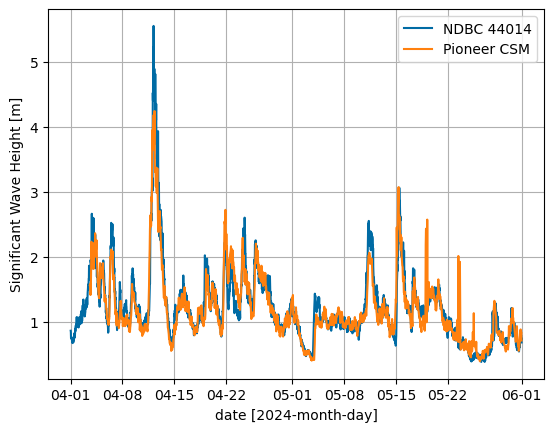

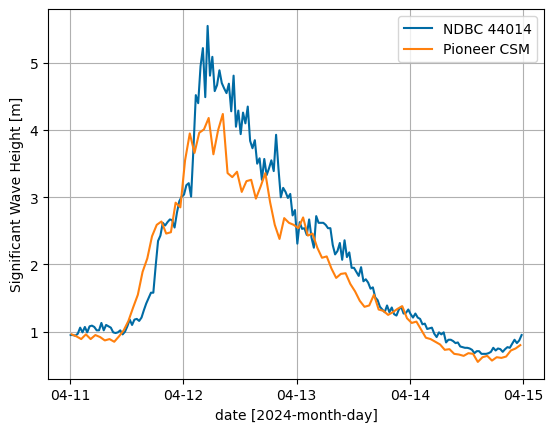

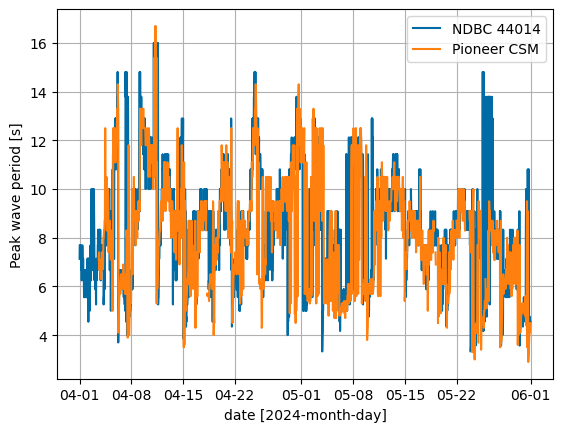

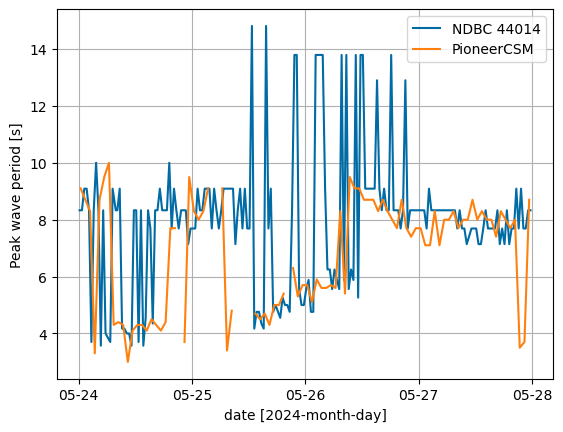

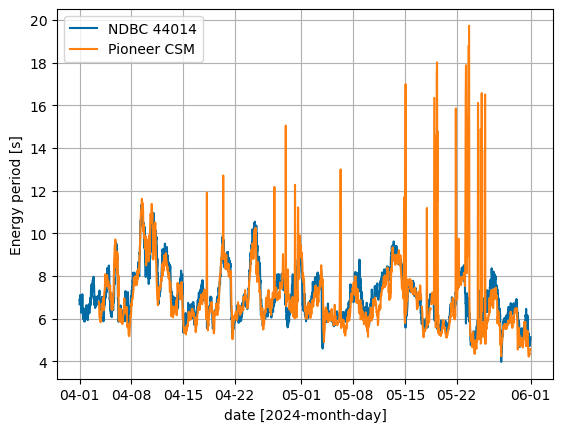

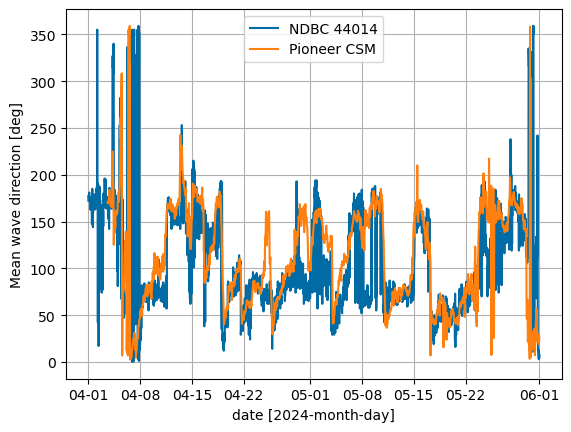

In [25]:
sig = ndbc_data.WVHT[np.flatnonzero(np.isfinite(ndbc_data.WVHT.values))]
pp = ndbc_data.DPD[np.flatnonzero(np.isfinite(ndbc_data.DPD.values))]
dir = ndbc_data.MWD[np.flatnonzero(np.isfinite(ndbc_data.MWD.values))]
ep = ndbc_energy_period.Te[np.flatnonzero(np.isfinite(ndbc_energy_period.Te.values))]

sig_pion = pioneer_data.significant_wave_height.where(pioneer_data.significant_wave_height < 9)
pp_pion = pioneer_data.peak_wave_period.where(pioneer_data.peak_wave_period < 20.0)
ep_pion = pioneer_non_directional_energy_period.Te.where(pioneer_non_directional_energy_period.Te < 20)
#ep_pion_dir = pioneer_directional_energy_period.Te.where(pioneer_directional_energy_period.Te < 400)

#print(ep_pion.values)

sig_bad = pioneer_data.significant_wave_height.where(pioneer_data.significant_wave_height > 9)
pp_bad = pioneer_data.peak_wave_period.where(pioneer_data.peak_wave_period > 20)



fig, ax = plt.subplots()
ax.plot(sig.time.values, sig.values)
ax.plot(sig_pion.time.values, sig_pion.values)
#ax.plot(sig_bad.time.values, sig_bad.values, 'x')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Significant Wave Height [m]')
plt.legend(['NDBC 44014', 'Pioneer CSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_hs_time")

fig.savefig('../../paperFigs/ndbc_pioneer_hs_time.pdf', bbox_inches='tight')

sig_reduced = sig.where(np.logical_and(sig.time > np.datetime64('2024-04-11'), sig.time < np.datetime64('2024-04-15')))
sig_pion_reduced = sig_pion.where(np.logical_and(sig_pion.time > np.datetime64('2024-04-11'), sig_pion.time < np.datetime64('2024-04-15')))

fig, ax = plt.subplots()
ax.plot(sig_reduced.time.values, sig_reduced.values)
ax.plot(sig_pion_reduced.time.values, sig_pion_reduced.values)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
#ax.plot(sig_bad.time.values, sig_bad.values, 'x')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Significant Wave Height [m]')
plt.legend(['NDBC 44014', 'Pioneer CSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_hs_all")


fig, ax = plt.subplots()
ax.plot(pp.time.values, pp.values)
ax.plot(pp_pion.time.values, pp_pion.values)
#ax.plot(pp_bad.time.values, pp_bad.values, 'x')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Peak wave period [s]')
plt.legend(['NDBC 44014', 'Pioneer CSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_hs_closeup")

pp_reduced = pp.where(np.logical_and(pp.time > np.datetime64('2024-05-24'), pp.time < np.datetime64('2024-05-28')))
pp_pion_reduced = pp_pion.where(np.logical_and(pp_pion.time > np.datetime64('2024-05-24'), pp_pion.time < np.datetime64('2024-05-28')))
fig, ax = plt.subplots()
ax.plot(pp_reduced.time.values, pp_reduced.values)
ax.plot(pp_pion_reduced.time.values, pp_pion_reduced.values)
#ax.plot(pp_bad.time.values, pp_bad.values, 'x')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Peak wave period [s]')
plt.legend(['NDBC 44014', 'PioneerCSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_pp_all")

fig, ax = plt.subplots()
plt.plot(ep.time.values, ep.values)
plt.plot(ep_pion.time.values, ep_pion.values)
#plt.plot(ep_pion_dir.time.values, ep_pion_dir.values)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Energy period [s]')
plt.legend(['NDBC 44014', 'Pioneer CSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_ep_all")

fig.savefig('../../paperFigs/ndbc_pioneer_ep_all.pdf', bbox_inches='tight')

fig, ax = plt.subplots()
ax.plot(dir.time.values, dir.values)
ax.plot(pioneer_data.port_timestamp.values, pioneer_data.mean_direction.values)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xlabel('date [2024-month-day]')
plt.ylabel('Mean wave direction [deg]')
plt.legend(['NDBC 44014', 'Pioneer CSM'])
plt.grid()
save_fig(fig, "ndbc_pioneer_dir_all")

fig.savefig('../../paperFigs/ndbc_pioneer_dir_all.pdf', bbox_inches='tight')


[array(64, dtype=int64), array(213, dtype=int64), array(36, dtype=int64), array(168, dtype=int64)]


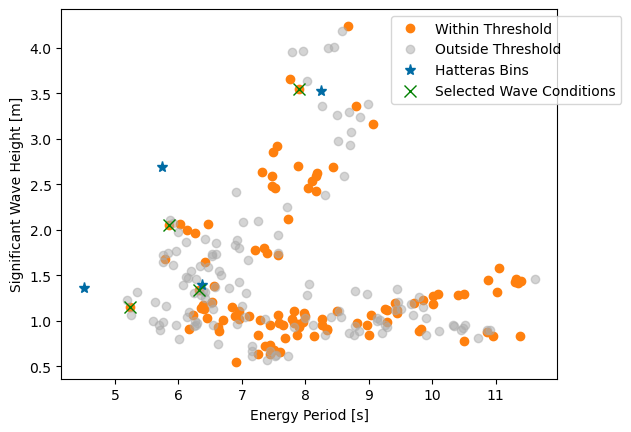

In [26]:
# selected points from Mark's diagram:
Hm0_bins = [1.36, 1.40, 2.69, 3.53]
Te_bins = [4.51, 6.37, 5.74, 8.24]

# Select data in range of Jantzen's data (pioneer IMU recordings) and plot significant wave height vs. energy period
Te_pnr = pioneer_non_directional_energy_period.where(pioneer_non_directional_energy_period.time < np.datetime64('2024-04-15T00:00:00'),drop=True)
Te_pnr = Te_pnr.where(Te_pnr.time > np.datetime64('2024-04-05T00:00:00'),drop=True)
Hm0_pnr = pioneer_data.significant_wave_height

Hm0_pnr = Hm0_pnr.where(Hm0_pnr.time < np.datetime64('2024-04-15T00:00:00'),drop=True)
Hm0_pnr = Hm0_pnr.where(Hm0_pnr.time > np.datetime64('2024-04-05T00:00:00'),drop=True)

ndbc_hourly = ndbc_data.coarsen(time=6, boundary="trim").mean()

Hm0_fit = []
Te_fit = []
Hm0_no_fit = []
Te_no_fit = []

Hm0_allowance = .5
Te_allowance = 1
dir_allowance = 25

for Te, Hm0 in zip(Te_pnr.Te,Hm0_pnr):
    select_obs = (pioneer_data.where(pioneer_data.time==Hm0.time.values,drop=True).obs.values)
    select_time = (pioneer_data.where(pioneer_data.time==Hm0.time.values,drop=True).time.values)
    nearestNDBC = ndbc_hourly.sel(time=select_time,method='nearest')
    nearestNDBC_ep = ndbc_energy_period.sel(time=select_time,method='nearest')
    nearestPioneer = pioneer_data.sel(obs=select_obs,method='nearest')
    nearestPioneer_ep = pioneer_non_directional_energy_period.sel(time=select_time,method='nearest')

    Hm0_diff = abs(nearestNDBC.WVHT.values - nearestPioneer.significant_wave_height.values)
    Te_diff = abs(nearestNDBC_ep.Te.values - nearestPioneer_ep.Te)
    dir_diff = abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)
    if dir_diff > 300:
        dir_diff = abs(abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)-360)

    if Hm0_diff > Hm0_allowance or Te_diff > Te_allowance or dir_diff > dir_allowance:
        Hm0_no_fit.append(Hm0)
        Te_no_fit.append(Te)
    else:
        Hm0_fit.append(Hm0)
        Te_fit.append(Te)
        

Hm0_diff = abs(nearestNDBC.WVHT.values - nearestPioneer.significant_wave_height.values)
Te_diff = abs(nearestNDBC_ep.Te.values - nearestPioneer_ep.Te)
dir_diff = abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)
if dir_diff > 300:
    dir_diff = abs(abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)-360)

Hm0_pnr_meets_criteria = Hm0_pnr.where(Hm0_pnr.time > np.datetime64('2024-04-05T00:00:00'),drop=True)


#print(Te_pnr.Te)

fig, ax = plt.subplots()
#plt.plot(Te_pnr.Te,Hm0_pnr,'o',label='Pioneer Data')
ax.plot(Te_fit,Hm0_fit,'o',label='Within Threshold',color='#FF800E')
ax.plot(Te_no_fit,Hm0_no_fit,'o',label='Outside Threshold',alpha=0.5,color='#ABABAB',)
ax.plot(Te_bins,Hm0_bins,'*',label='Hatteras Bins',markersize=8,color='#006BA4')
ax.set_xlabel('Energy Period [s]')
ax.set_ylabel('Significant Wave Height [m]')
#plt.title('Pioneer Data compared to Hatteras Bins')

SS_ind = []

for Te_bin, Hm0_bin in zip(Te_bins,Hm0_bins):
    newTe_pnr = Te_pnr.Te
    newHm0_pnr = Hm0_pnr
    minArgInd = 0
    Hm0_diff = np.inf
    Te_diff = np.inf
    dir_diff = np.inf
    SS_last = np.inf

    while Hm0_diff > Hm0_allowance or Te_diff > Te_allowance or dir_diff > dir_allowance:

        errorTot = (abs(2*(newTe_pnr-Te_bin)) + abs(newHm0_pnr.values-Hm0_bin))
        SS = np.argsort(errorTot)[minArgInd]
        #print(SS)

        # check match between pioneer and NDBC
        #print(SS)
        #print(newHm0_pnr[SS].time.values)
        #print(newHm0_pnr)
        select_obs = (pioneer_data.where(pioneer_data.time==newHm0_pnr[SS.values].time.values,drop=True).obs.values)
        select_time = (pioneer_data.where(pioneer_data.time==newHm0_pnr[SS.values].time.values,drop=True).time.values)
        #SS_obs = Hm0_pnr.sel(time=select_time,method='nearest').obs.values

        nearestNDBC = ndbc_hourly.sel(time=select_time,method='nearest')
        nearestNDBC_ep = ndbc_energy_period.sel(time=select_time,method='nearest')
        nearestPioneer = pioneer_data.sel(obs=select_obs,method='nearest')
        nearestPioneer_ep = pioneer_non_directional_energy_period.sel(time=select_time,method='nearest')

        Hm0_diff = abs(nearestNDBC.WVHT.values - nearestPioneer.significant_wave_height.values)
        Te_diff = abs(nearestNDBC_ep.Te.values - nearestPioneer_ep.Te)
        dir_diff = abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)
        if dir_diff > 300:
            dir_diff = abs(abs(nearestNDBC.MWD.values - nearestPioneer.mean_direction.values)-360)

        minArgInd = minArgInd + 1
        SS_last = SS

    SS_ind.append(SS.values)

newTe_pnr = Te_pnr.Te

ax.plot(newTe_pnr[SS_ind],Hm0_pnr[SS_ind],'x',label='Selected Wave Conditions',markersize=8,color='green')
ax.legend(bbox_to_anchor=(.65, 1))

print(SS_ind)

fig.savefig('../../paperFigs/waveConditionSelection.pdf', bbox_inches='tight')


In [27]:
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])

['#006BA4', '#FF800E', '#ABABAB', '#595959', '#5F9ED1', '#C85200', '#898989', '#A2C8EC', '#FFBC79', '#CFCFCF']


Text(0.5, 1.0, 'NDBC Data')

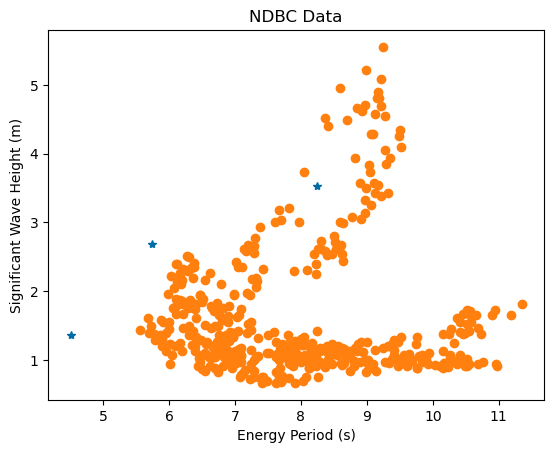

In [28]:
# let's plot NDBC during this same time
# Select data in range of Jantzen's data (pioneer IMU recordings) and plot significant wave height vs. energy period
Te_NDBC = ndbc_energy_period.where(ndbc_energy_period.time < np.datetime64('2024-04-15T00:00:00'),drop=True)
Te_NDBC = Te_NDBC.where(Te_NDBC.time > np.datetime64('2024-04-05T00:00:00'),drop=True)
Hm0_NDBC = ndbc_data.WVHT

Hm0_NDBC = Hm0_NDBC.where(Hm0_NDBC.time < np.datetime64('2024-04-15T00:00:00'),drop=True)
Hm0_NDBC = Hm0_NDBC.where(Hm0_NDBC.time > np.datetime64('2024-04-05T00:00:00'),drop=True)

Hm0_NDBC = Hm0_NDBC.where(Hm0_NDBC.time == Te_NDBC.time)

Te_NDBC = Te_NDBC.where(Te_NDBC.time == Hm0_NDBC.time)

plt.figure()
plt.plot(Te_bins,Hm0_bins,'*')
plt.plot(Te_NDBC.Te,Hm0_NDBC,'o')
plt.xlabel('Energy Period (s)')
plt.ylabel('Significant Wave Height (m)')
plt.title('NDBC Data')

In [29]:
# Find time of the selected points to see them on matching plots
pnr_selected = []
selected_obs = []
selected_times = []

for SS in SS_ind:
    pnr_selected.append(pioneer_data.where(pioneer_data.time==Hm0_pnr[SS].time,drop=True))
    selected_obs.append(pioneer_data.where(pioneer_data.time==Hm0_pnr[SS].time,drop=True).obs.values)
    selected_times.append(pioneer_data.where(pioneer_data.time==Hm0_pnr[SS].time,drop=True).time.values)

ndbc_hourly = ndbc_data.coarsen(time=6, boundary="trim").mean()

# extract data for snips
#snips = [202, 419, 313, 349]
#snipTimes = [datetime.datetime(2024,4,7,18), datetime.datetime(2024,4,13,19), datetime.datetime(2024,4,11,14), datetime.datetime(2024,4,12,8)]
#snipRawTimes = [3.921503010698000e+09, 3.922025011357000e+09, 3.921834210532000e+09, 3.921899010806000e+09]
#obsNumber = [101, 246, 193, 211]

dataHeaders = ["Raw Time","Time","Obs","NDBC Time","Pioneer Time","NDBC Dir","NDBC TP","NDBC Hm0","Pioneer Dir","Pioneer Tp","Pioneer Hm0"]
dataTable = []

nearestPioneer = pioneer_data.sel(obs=selected_obs[0]-1,method='nearest')
#print(nearestPioneer)
pioneer_data_raw = xr.load_dataset(pjoin(raw_data_dir,  "ooiSpectra-mab", "deployment0001_CP10CNSM-SBD12-05-WAVSSA000-telemetered-wavss_a_dcl_statistics_20240403T142323.911000-20240606T162324.628000.nc"),decode_times=False)

for snipTime, obsNum in zip(selected_times,selected_obs):
    nearestNDBC = ndbc_hourly.sel(time=snipTime,method='nearest')
    nearestNDBC_ep = ndbc_energy_period.sel(time=snipTime,method='nearest')
    nearestPioneer = pioneer_data.sel(obs=obsNum,method='nearest')
    nearestPioneer_ep = pioneer_non_directional_energy_period.sel(time=snipTime,method='nearest')
    nearestPioneer_raw = pioneer_data_raw.sel(obs=obsNum,method='nearest')
    dataTable.append([nearestPioneer_raw.time,snipTime,obsNum,str(nearestNDBC.time.values),str(nearestPioneer.time.values),nearestNDBC.MWD.values,nearestNDBC_ep.Te.values,nearestNDBC.WVHT.values,nearestPioneer.mean_direction.values,nearestPioneer_ep.Te,nearestPioneer.significant_wave_height.values])

# display table
print(tabulate(dataTable, headers=dataHeaders, tablefmt="grid")) # , floatfmt=".3f"


+-------------+-------------+-------+-----------------------------------+-----------------------------------+------------+-----------+------------+---------------+--------------+---------------+
|    Raw Time |        Time |   Obs | NDBC Time                         | Pioneer Time                      |   NDBC Dir |   NDBC TP |   NDBC Hm0 |   Pioneer Dir |   Pioneer Tp |   Pioneer Hm0 |
+=============+=============+=======+===================================+===================================+============+===========+============+===============+==============+===============+
| 3.9215e+09  | 1.71251e+18 |    98 | ['2024-04-07T16:25:00.000000000'] | ['2024-04-07T16:23:23.066999808'] |        5   |   6.00635 |      1.5   |          25.1 |      5.24194 |          1.15 |
+-------------+-------------+-------+-----------------------------------+-----------------------------------+------------+-----------+------------+---------------+--------------+---------------+
| 3.92203e+09 | 1.71304e+

In [30]:
# Need to find what the raw date is for the selected observations



for snipTime, obsNum in zip(selected_times,selected_obs):
    nearestPioneer = pioneer_data_raw.sel(obs=obsNum,method='nearest')
    

2024-04-03T14:23:23.911000064


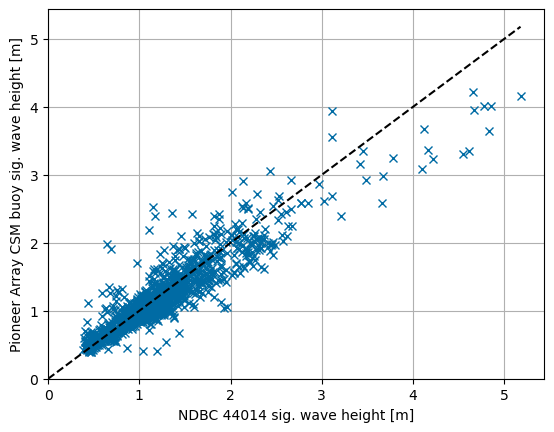

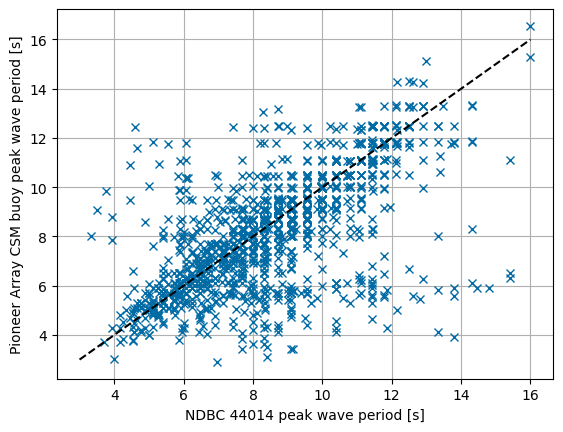

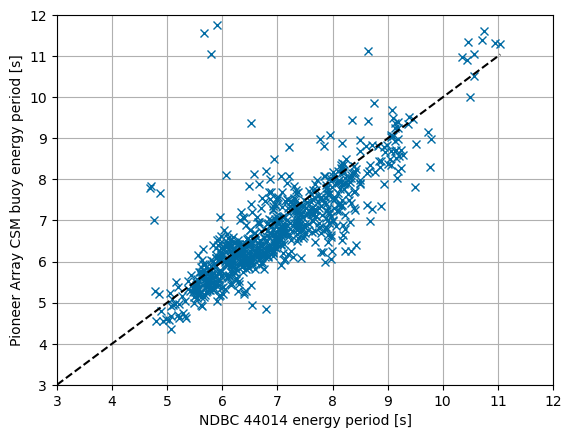

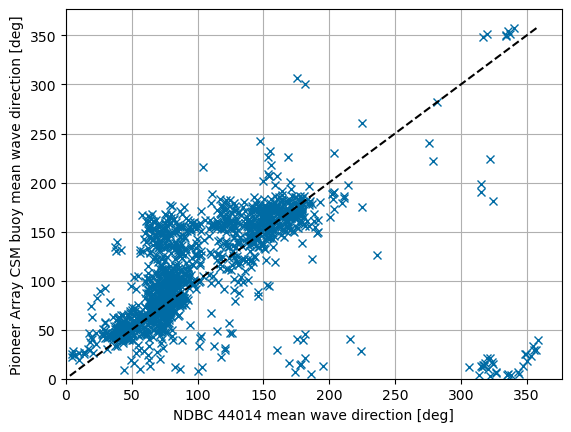

In [31]:
ndbc_hourly = ndbc_data.coarsen(time=6, boundary="trim").mean()

ndbc_energy_period_hourly = ndbc_energy_period.coarsen(time=2, boundary="trim").mean()

pioneer_start = pioneer_data.time.values[0]
print(pioneer_start)

ndbc_hourly = ndbc_hourly.drop_vars(["VIS", "TIDE"])

ndbc_hourly_sig = ndbc_hourly.WVHT.where(ndbc_hourly.time > pioneer_start).dropna("time")
ndbc_hourly_pp = ndbc_hourly.DPD.where(ndbc_hourly.time > pioneer_start).dropna("time")
ndbc_hourly_dir = ndbc_hourly.MWD.where(ndbc_hourly.time > pioneer_start).dropna("time")
ndbc_hourly_ep = ndbc_energy_period_hourly.Te.where(ndbc_hourly.time > pioneer_start).dropna("time")

ndbc_time_int = ndbc_hourly_sig.time.values.astype("datetime64[s]").astype("int")
ndbc_time_ep_int = ndbc_hourly_ep.time.values.astype("datetime64[s]").astype("int")
pioneer_time_int = pioneer_data.time.values.astype("datetime64[s]").astype("int")
pioneer_ep_time_int = pioneer_non_directional_energy_period.time.values.astype("datetime64[s]").astype("int")

pioneer_sig_interp = np.interp(ndbc_time_int, pioneer_time_int, sig_pion.values)
pioneer_pp_interp = np.interp(ndbc_time_int, pioneer_time_int, pp_pion.values)
pioneer_dir_interp = np.interp(ndbc_time_int, pioneer_time_int, pioneer_data.mean_direction.values)
pioneer_ep_interp = np.interp(ndbc_time_ep_int, pioneer_ep_time_int, ep_pion.values) 

fig, ax = plt.subplots()
ax.plot(ndbc_hourly_sig.values, pioneer_sig_interp, 'x')
ax.plot(np.linspace(0, np.max(ndbc_hourly_sig.values)), np.linspace(0, np.max(ndbc_hourly_sig.values)), 'k--')
plt.xlabel('NDBC 44014 sig. wave height [m]')
plt.ylabel('Pioneer Array CSM buoy sig. wave height [m]')
#plt.legend(['significant wave height [m]'])
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid()
save_fig(fig, "comp_hs")

fig.savefig('../../paperFigs/ndbc_pioneer_comp_hs.pdf', bbox_inches='tight')

fig, ax = plt.subplots()
ax.plot(ndbc_hourly_pp.values, pioneer_pp_interp, 'x')
ax.plot(np.linspace(3, np.max(ndbc_hourly_pp.values)), np.linspace(3, np.max(ndbc_hourly_pp.values)), 'k--')
plt.xlabel('NDBC 44014 peak wave period [s]')
plt.ylabel('Pioneer Array CSM buoy peak wave period [s]')
#plt.legend(['peak wave period [s]'])
plt.grid()
save_fig(fig, "comp_pp")

fig, ax = plt.subplots()
ax.plot(ndbc_hourly_ep.values, pioneer_ep_interp, 'x')
ax.plot(np.linspace(3, np.max(ndbc_hourly_ep.values)), np.linspace(3, np.max(ndbc_hourly_ep.values)), 'k--')
# plt.plot(np.linspace(3, np.max(ndbc_hourly_ep.values)), 1.3333 * np.linspace(3, np.max(ndbc_hourly_ep.values)), 'r--')
plt.xlabel('NDBC 44014 energy period [s]')
plt.ylabel('Pioneer Array CSM buoy energy period [s]')
#plt.legend(['energy period [s]'])
plt.grid()
plt.ylim(3, 12) 
plt.xlim(3, 12) 
save_fig(fig, "comp_ep")

fig.savefig('../../paperFigs/ndbc_pioneer_comp_ep.pdf', bbox_inches='tight')

fig, ax = plt.subplots()
ax.plot(ndbc_hourly_dir.values, pioneer_dir_interp, 'x')
ax.plot(np.linspace(3, np.max(ndbc_hourly_dir.values)), np.linspace(3, np.max(ndbc_hourly_dir.values)), 'k--')
plt.xlabel('NDBC 44014 mean wave direction [deg]')
plt.ylabel('Pioneer Array CSM buoy mean wave direction [deg]')
#plt.legend(['mean wave direction [deg]'])
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.grid()
save_fig(fig, "comp_dir")
fig.savefig('../../paperFigs/ndbc_pioneer_comp_dir.pdf', bbox_inches='tight')
